# M03-4 | 共用 qparams：SharedQuantizationSpec 與隱式共用

兩個 int8 tensor 要做整數加法（或 concat）時，必須在同一個尺度上：scale 不同的整數不能直接相加，硬體得先 rescale 其中一個。
所以有些後端要求 **add、cat 的所有輸入與輸出共用同一組 (scale, zero point)**。

在 PT2E 裡，「共用 qparams」的做法是讓幾個位置共用**同一個 observer 實例**：這個 observer 看過所有位置的數值，算出一組 scale，大家一起用。
共用有兩種來源：

- **顯式**：標籤的規格寫 `SharedQuantizationSpec(某個位置)`，意思是「和那個位置用同一個 observer」。
- **隱式**：同一個 tensor 上的兩張標籤屬性相同時，`prepare_pt2e` 自動合併成一個 observer。M03-1 的 C 段提過。

段落：

- **A.** 顯式共用：讓 add 的輸入與輸出共用一組 qparams。
- **B.** 隱式共用：同一個 tensor 同時有輸出標籤與邊標籤時，什麼時候合併、什麼時候串接。

In [1]:
import copy

import torch
from torch.fx import Node

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    MovingAverageMinMaxObserver,
    QuantizationSpec,
    Quantizer,
    SharedQuantizationSpec,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)
ADD = torch.ops.aten.add.Tensor

## A. 顯式共用：SharedQuantizationSpec

`AddQuantizer` 用 `node.target` 找所有 add。第一個輸入邊用一般的 spec；`share=True` 時，其餘的輸入邊與輸出都寫
`SharedQuantizationSpec((第一個輸入, add))`：參數是一個**位置**，邊用 `(producer, consumer)`，node 的輸出直接給 node。

只有 activation 才需要標籤，所以要排除兩種輸入：`add(x, 1.0)` 的 Python 純量（不是 `Node`，不能當 `input_qspec_map` 的 key），
以及 `add(x, self.b)` 的模型常數（`get_attr`）。`add(x, x)` 兩個輸入是同一個 node，要去重。

In [2]:
class AddQuantizer(Quantizer):
    def __init__(self, share: bool):
        self.share = share

    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op != "call_function" or node.target != ADD:
                continue
            ann = node.meta.get(ANNOTATION_KEY)
            if ann is not None and ann._annotated:
                continue
            inputs = list(dict.fromkeys(a for a in node.args[:2] if isinstance(a, Node) and a.op != "get_attr"))
            if not inputs:
                continue
            spec = act_spec()
            annotate_input_qspec_map(node, inputs[0], spec)
            rest = SharedQuantizationSpec((inputs[0], node)) if self.share else spec  # 和「第一個輸入 → add」共用
            for other in inputs[1:]:
                annotate_input_qspec_map(node, other, rest)
            annotate_output_qspec(node, rest)
            node.meta[ANNOTATION_KEY]._annotated = True
        return model

    def validate(self, model):
        pass

第一個模型只有一個 add，兩個輸入的範圍刻意差很多（`b` 是 `a` 的 5 倍）。共用與不共用各 prepare 一次、校準，圖上的 observer 會顯示算出的 scale：

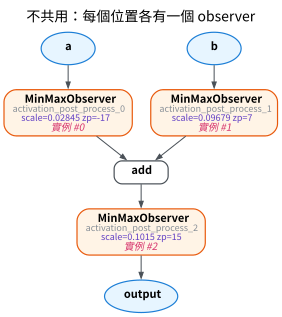

In [3]:
class AddOnly(torch.nn.Module):
    def forward(self, a, b):
        return a + b


def make_inputs():
    return torch.randn(4, 8), torch.randn(4, 8) * 5


def prepare_add(gm, share, make_inputs):
    prepared = prepare_pt2e(copy.deepcopy(gm), AddQuantizer(share))
    with torch.no_grad():
        for _ in range(8):
            prepared(*make_inputs())
    return prepared


def instance_notes(prepared):
    """每個 observer node 標上它用的是第幾個 observer 實例。"""
    number: dict[int, int] = {}
    return {n.name: f"實例 #{number.setdefault(id(mod), len(number))}" for n, mod in observer_nodes(prepared)}


gm_add = export_module(AddOnly(), make_inputs())
separate = prepare_add(gm_add, False, make_inputs)
draw(separate, notes=instance_notes(separate), title="不共用：每個位置各有一個 observer")

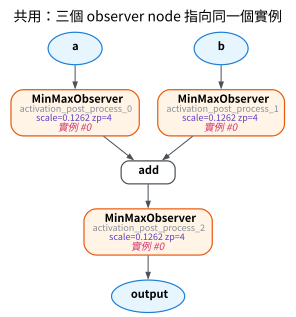

In [4]:
shared = prepare_add(gm_add, True, make_inputs)
draw(shared, notes=instance_notes(shared), title="共用：三個 observer node 指向同一個實例")

In [5]:
def summary(prepared):
    mods = [mod for _, mod in observer_nodes(prepared)]
    scales = sorted({round(float(m.calculate_qparams()[0]), 6) for m in mods})
    return len(mods), len({id(m) for m in mods}), scales


for title, p in [("不共用", separate), ("共用", shared)]:
    n_nodes, n_instances, scales = summary(p)
    print(f"{title}：observer node {n_nodes} 個、實例 {n_instances} 個、scale {scales}")
assert summary(separate)[1] == 3 and summary(shared)[1] == 1

不共用：observer node 3 個、實例 3 個、scale [0.028452, 0.09679, 0.101465]
共用：observer node 3 個、實例 1 個、scale [0.126223]


- 不共用：三個位置各算各的 scale，`b` 的範圍大，它的 scale 也大。
- 共用：圖上仍有三個 observer node（每個位置都要被觀察），但它們是同一個 observer 實例。這個實例看過 `a`、`b` 和輸出的所有數值，算出一組涵蓋全部的 scale。

同一個 `AddQuantizer` 不需要知道模型長什麼樣。換成 residual 模型（add 的輸入是 conv 的輸出與 skip connection 的 `x`），只畫 add 附近：

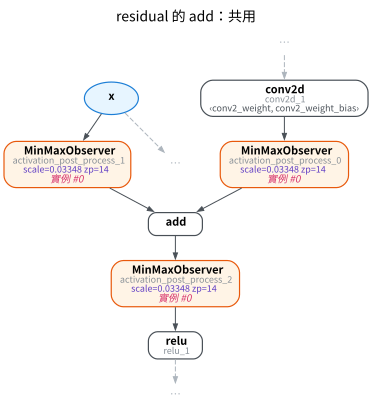

In [6]:
gm_res = export_module(get_model("residual").eval(), example_inputs(4))
res_shared = prepare_add(gm_res, True, lambda: (torch.randn(4, 3, 16, 16),))
draw(res_shared, focus="add", hops=2, notes=instance_notes(res_shared), title="residual 的 add：共用")

In [7]:
n_nodes, n_instances, _ = summary(res_shared)
print(f"observer node {n_nodes} 個、實例 {n_instances} 個")
assert n_instances == 1 and n_nodes == 3

observer node 3 個、實例 1 個


## B. 隱式共用：輸出標籤 + 邊標籤

M03-1 的 C 段看過：同一個 tensor 可以有**輸出標籤**（影響所有 consumer），也可以有**邊標籤**（只影響一個 consumer）。
兩張都貼的時候會發生什麼？

用 `cat_pool` 模型（輸入 `x` 同時餵給 `conv2d` 與 `conv2d_1`）。`TwoLabelQuantizer` 在 `x` 的輸出貼 spec A，在邊 `x → conv2d_1` 貼 spec B。
它是為了這個實驗點名寫的，node 名稱只適用 `cat_pool`。`allow_implicit_sharing` 是 `QuantizationAnnotation` 的欄位（預設 `True`），設成 `False` 可以關掉合併。

In [8]:
class TwoLabelQuantizer(Quantizer):
    def __init__(self, spec_a, spec_b, implicit=True):
        self.spec_a, self.spec_b, self.implicit = spec_a, spec_b, implicit

    def annotate(self, model):
        nodes = {n.name: n for n in model.graph.nodes}
        annotate_output_qspec(nodes["x"], self.spec_a)
        annotate_input_qspec_map(nodes["conv2d_1"], nodes["x"], self.spec_b)
        nodes["conv2d_1"].meta[ANNOTATION_KEY].allow_implicit_sharing = self.implicit
        return model

    def validate(self, model):
        pass

四種情況的 spec B：

In [9]:
a = act_spec()  # int8 per-tensor affine [-128, 127]，MinMaxObserver
different = QuantizationSpec(  # qscheme 與整數範圍都和 A 不同
    dtype=torch.int8, quant_min=-127, quant_max=127, qscheme=torch.per_tensor_symmetric,
    observer_or_fake_quant_ctr=a.observer_or_fake_quant_ctr,
)
other_observer = QuantizationSpec(  # 量化屬性和 A 完全相同，只有 observer 類別不同
    dtype=a.dtype, quant_min=a.quant_min, quant_max=a.quant_max, qscheme=a.qscheme,
    observer_or_fake_quant_ctr=MovingAverageMinMaxObserver,
)
cases = [
    ("B 與 A 屬性不同", TwoLabelQuantizer(a, different)),
    ("B 與 A 屬性相同", TwoLabelQuantizer(a, a)),
    ("屬性相同，但 allow_implicit_sharing=False", TwoLabelQuantizer(a, a, implicit=False)),
    ("B 與 A 只有 observer 類別不同", TwoLabelQuantizer(a, other_observer)),
]

每種情況都 prepare、校準、convert，印出 `x` 走到 `conv2d_1` 的路上經過什麼（obs = observer，q／dq = quantize／dequantize）：

In [10]:
def path_to(gm, consumer):
    """x 走到 consumer 的路上依序經過的 node。"""
    steps, src = [], next(n for n in gm.graph.nodes if n.name == consumer).args[0]
    while src.op != "placeholder":
        target = str(src.target)
        steps.append("obs" if src.op == "call_module" else "dq" if "dequantize" in target else "q")
        src = src.args[0]
    return " → ".join(["x", *reversed(steps), consumer])


gm_cat = export_module(get_model("cat_pool").eval(), example_inputs(4))
rows = []
for title, quantizer in cases:
    prepared = prepare_pt2e(copy.deepcopy(gm_cat), quantizer)
    obs = observer_nodes(prepared)
    kinds = ", ".join(sorted({type(m).__name__ for _, m in obs}))
    before = path_to(prepared, "conv2d_1")
    with torch.no_grad():
        for _ in range(4):
            prepared(torch.randn(4, 3, 16, 16))
    rows.append([title, len(obs), kinds, before, path_to(convert_pt2e(prepared), "conv2d_1")])
table(rows, ["情況", "observer 數", "observer 類別", "prepare 之後", "convert 之後"])

情況,observer 數,observer 類別,prepare 之後,convert 之後
B 與 A 屬性不同,2,MinMaxObserver,x → obs → obs → conv2d_1,x → q → dq → q → dq → conv2d_1
B 與 A 屬性相同,1,MinMaxObserver,x → obs → conv2d_1,x → q → dq → conv2d_1
屬性相同，但 allow_implicit_sharing=False,2,MinMaxObserver,x → obs → obs → conv2d_1,x → q → dq → q → dq → conv2d_1
B 與 A 只有 observer 類別不同,1,MinMaxObserver,x → obs → conv2d_1,x → q → dq → conv2d_1


In [11]:
assert [r[1] for r in rows] == [2, 1, 2, 1]
assert rows[0][4] == "x → q → dq → q → dq → conv2d_1" and rows[1][4] == "x → q → dq → conv2d_1"
assert rows[3][2] == "MinMaxObserver"

1. **屬性不同：兩張標籤串接**。`x` 先被 A 量化，再被 B 量化一次，convert 之後是兩層 q/dq，捨入兩次。不是誰覆蓋誰，也不會報錯。
2. **屬性相同：自動合併成一個 observer**，只量化一次。它們本來就是同一個 tensor，沒必要量化兩次，這就是隱式共用。
3. **`allow_implicit_sharing=False`**：不合併，回到兩個 observer 串接。關掉之後要自己負責同一個 tensor 不被量化兩次。
4. **比的是量化屬性（dtype、整數範圍、qscheme…），不比 observer 類別**。只有 observer 類別不同時也會合併，
   留下的是 A 的 `MinMaxObserver`，B 指定的 `MovingAverageMinMaxObserver` 被默默忽略（這張圖上 A 的標籤在 graph 順序上先出現）。

要讓同一個 tensor 只量化一次：讓所有標籤的屬性一致，或明確用 `SharedQuantizationSpec` 指向同一個位置。

## 小結

- 共用 qparams = 幾個位置共用同一個 observer 實例；圖上仍是好幾個 observer node。
- 顯式：`SharedQuantizationSpec(位置)`，位置是 `(producer, consumer)` 的邊或一個 node 的輸出。
- 隱式：同一個 tensor 上屬性相同的標籤自動合併；屬性不同則串接成兩次量化，不報錯。